# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here
we render them as deliverables (**raw** per-cell scores, so inDrop dropout is visible) and evaluate
**Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into *distinct
arms* radiating from a co-expression hub, with Crest terminal. Zilionis 2019 instead shows the
§1 (Wu 2021) **non-branching** pattern: **organized Gast↔pSom cross-repression** along a single
axis (smoothed spatial r ≈ −0.58 — Gast-high origin opposing a pSom-high end) with **no
co-expression hub** (co-high enrichment 0.73 < 1), and an **inverse neural-crest gradient**
opposing both (Crest↔Gast r ≈ −0.47, Crest↔pSom r ≈ −0.37). Along pseudotime Gast falls
(rho ≈ −0.60) while pSom rises (rho ≈ +0.78); Crest is interior/inverse rather than a single sharp
terminal tip. Organized cross-repression with an inverse Crest gradient **passes** — **Gate 2 =
GO**; with no bifurcation the cross-repression test is **Gate 3 = NA**.

**Crest-arm check (§2 flag).** Crest is inverse to *both* developmental modules and is not enriched
on a Gast arm (there is no arm) — so the Crest-on-Gast-arm inversion flag does **not** apply.

**The gate is geography, not means.** The raw module means (Gast −0.009 / pSom +0.039 / Crest
−0.023) are pSom-leaning with Crest negative — the common Linear profile. What decides GO is the
*geography*: coherent cross-repression with an inverse Crest gradient. Deliverable:
`signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 3920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography on the manifold
Quantitative support for the non-branching read: (i) Gast↔pSom spatial cross-repression (negative);
(ii) Crest opposes both in space; (iii) no Gast/pSom co-expression hub (co-high enrichment < 1);
(iv) along pseudotime Gast falls and pSom rises; (v) the joint Gast&pSom-high enrichment tests
hub vs cross-repression (a Puram co-expression hub would be > 1).

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.58
  Crest_sm vs Gast_sm: r = -0.47
  Crest_sm vs pSom_sm: r = -0.37
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.595
  pSom_sm: rho = +0.778
  Crest_sm: rho = +0.003
Gast&pSom co-high enrichment = 0.73 (<1 = cross-repression, not a co-expression hub)
Neural-crest-high decile mean pseudotime = 0.50 (inverse/interior, not a single terminal tip)
Gate 2: organized Gast<->pSom cross-repression + inverse Crest gradient, no co-expression hub -> GO (non-branching)
Gate 3: no bifurcation -> NA
Crest-arm flag: Crest inverse to BOTH modules, not enriched on a Gast arm -> flag N/A


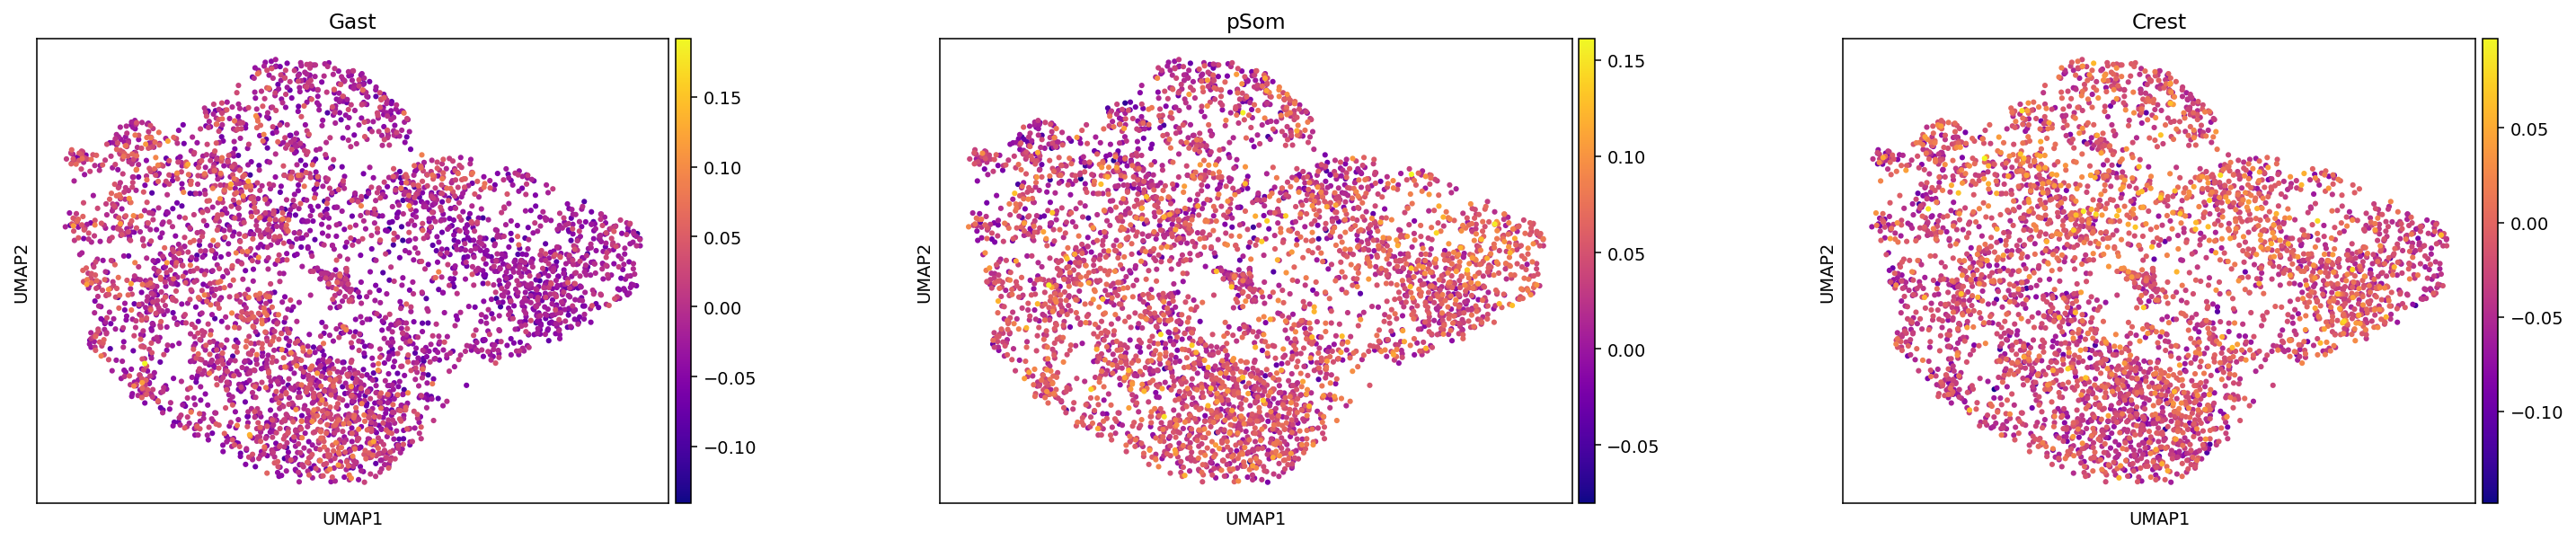

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
gz = (adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
joint = ((gz>0.5)&(pz>0.5)).mean(); exp = (gz>0.5).mean()*(pz>0.5).mean()
print(f'Gast&pSom co-high enrichment = {joint/exp:.2f} (<1 = cross-repression, not a co-expression hub)')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (inverse/interior, not a single terminal tip)')
print('Gate 2: organized Gast<->pSom cross-repression + inverse Crest gradient, no co-expression hub -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')
print('Crest-arm flag: Crest inverse to BOTH modules, not enriched on a Gast arm -> flag N/A')
sc.pl.umap(adata, color=['Gast','pSom','Crest'], size=40, cmap='plasma', wspace=.3)

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma, **raw**
(not smoothed) score per cell so inDrop dropout is visible. Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


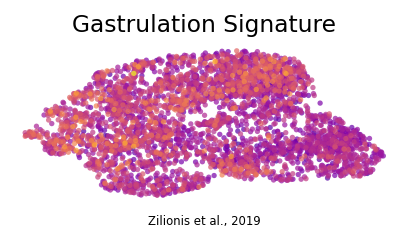

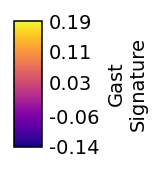

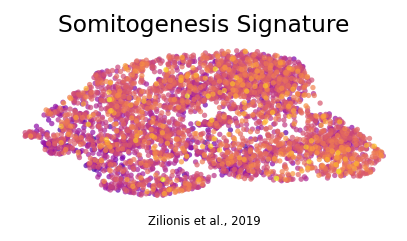

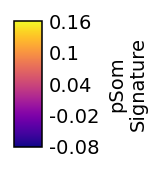

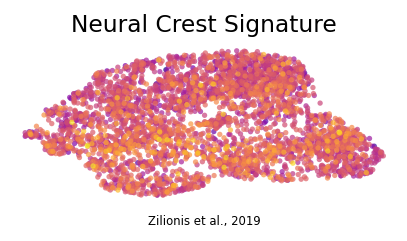

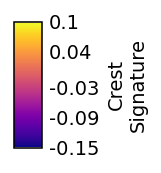

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3920, 28282)
